:::{list-table}
:header-rows: 1
:align: center
:widths: 90 10
* - #
    # Fondamenti di programmazione
    # Canale A-L - Prof. M. Mancini
    # AA 26-27 - Lezione 08
  - :::{image}attachment:5a837f06-202c-4c6e-9259-dd7a6dc01c97.png
    :width: 200px
    :::
:::

# RECAP: Files
```python
# apro il file e metto nella variabile F l'oggetto che ottengo
with open(<filename>, mode=<mode>, encoding='utf8') as F:
     codice che legge/scrive il file F
     # uscendo dal with il file viene chiuso automagicamente 😎
```
Una volta aperto il file **F** potete usare i metodi:
- **`F.read()`** legge tutto il contenuto (o una sua parte)
- **`F.readline()`** legge UNA riga (compreso **`'\n'`**)
- **`F.readlines()`** legge TUTTE le righe (compresi **`'\n'`**) e torna una lista
- **`F.write(<string>)`** scrive un testo nel file (dovete aggiungere voi `'\n'`)
- **`print( ..., file=F)`** stampa nel file (molto comodo)
- **`F.seek(0)`** torna alla posizione 0 (inizio)

# Come trovare le parole contenute in un file?
- distinguiamo le lettere alfabetiche (che ci servono)
- dal resto che usiamo come separatore
- e magari trasformiamo tutto in minuscole

Altre considerazioni
- e se una parola è spezzata da una andata a capo?
- e se una parola è contiene un trattino? un apostrofo?


Per leggere le parole da un file di testo
- apriamo il file in modo testo con l'encoding giusto
- leggiamo il testo
- lo trasformiamo in minuscole
- troviamo le lettere non alfabetiche (sottoproblema)
- le sostituiamo con spazi (sottoproblema)
- splittiamo il testo e otteniamo le parole

In [1]:
def leggi_parole(filename, encoding):
    with open(filename, encoding=encoding) as F:  # apriamo il file
        testo = F.read()                          # leggo tutto il contenuto
    testo = testo.lower()                         # lo metto in minuscole
    nonalfa = trova_nonalfa(testo)                # trovo i caratteri NON alfabetici
    testo = rimpiazza_con_spazi2(testo, nonalfa)  # li sostituisco con spazi
    return testo.split()                          # spezzo il testo in parole

In [2]:
def trova_nonalfa(testo : str) -> set[str] :
    caratteri = set(testo)                        # trovo i caratteri usati
    # e ne estraggo i NON alfabetici
    return { c for c in caratteri if not c.isalpha()  }

In [3]:
def rimpiazza_con_spazi(testo : str, nonalfa : set[str]) -> str :
    for carattere in nonalfa:
        testo = testo.replace(carattere, ' ')
    return testo

### Per trasformare più caratteri in un solo passaggio uso `str.translate`
- ha bisogno di un dizionario     **char_code -> stringa**
- che posso costruire con `str.maketrans` partendo da un dizionario **carattere -> stringa**

In [4]:
def rimpiazza_con_spazi2(testo : str, nonalfa : set[str]) -> str :
    # oppure un unico translate di più caratteri a spazi
    tra = str.maketrans(dict.fromkeys(nonalfa,' ')) # creo il mapping nonalpha -> spazio
    return testo.translate(tra)                     # applico la sostituzione dei nonalpha

In [5]:
## str.translate vuole un dizionario     char_code -> carattere
nonalfa = "!\"£$%&/()"
D = dict.fromkeys(nonalfa,' ')
T = str.maketrans(D)
print('char     -> char', D, '\ncharcode -> char', T) 

char     -> char {'!': ' ', '"': ' ', '£': ' ', '$': ' ', '%': ' ', '&': ' ', '/': ' ', '(': ' ', ')': ' '} 
charcode -> char {33: ' ', 34: ' ', 163: ' ', 36: ' ', 37: ' ', 38: ' ', 47: ' ', 40: ' ', 41: ' '}


In [6]:
parole = leggi_parole('files/alice_it.txt', 'latin')
print(parole[:30])

['charles', 'lutwidge', 'dodgson', 'alice', 'nel', 'paese', 'delle', 'meraviglie', 'questo', 'e', 'book', 'è', 'stato', 'realizzato', 'anche', 'grazie', 'al', 'sostegno', 'di', 'e', 'text', 'editoria', 'web', 'design', 'multimedia', 'http', 'www', 'e', 'text', 'it']


# ANALISI: Come trovare il file più importante dato un gruppo di parole cercate?
**PURTROPPO** Le parole <u>più frequenti</u> sono in genere <u>troppo comuni e poco significative</u>
(con poco contenuto semantico)

Esempio: articoli, verbi ausiliari, preposizioni, avverbi, parole comuni ...

Quindi una parola sarà "interessante" se <u>**appare spesso in un file**</u> ma <u>**appare in pochi file**</u>.

Calcoliamo:
- appare spesso in un file?: **Term Frequency** (tf) la frequenza percentuale della parola nel file
- appare in pochi file?: **Inverse Document Frequency** (idf) la percentuale di file che la contiene

Vedi https://en.wikipedia.org/wiki/tf-idf

# TF: Term Frequency (frequenza % di una parola in ciascun file)
- per ciascun file
  - contiamo le parole
  - dividiamo per il numero totale di parole

In [7]:
# ho un elenco di documenti con il loro encoding, ottenuti unzippando files.zip
files : dict[str,str] = {
    'files/holmes.txt'       : 'utf-8-sig', 
    'files/alice.txt'        : 'utf-8-sig', 
    'files/frankenstein.txt' : 'utf-8-sig', 
    'files/alice_it.txt'     : 'latin', 
    'files/prince.txt'       : 'utf-8-sig'
    }

In [8]:
# esempio: parole del libro Alice nel paese delle meraviglie
parole = leggi_parole('files/alice_it.txt', 'latin')

### NOTA: come usare meno memoria? lavorando riga per riga
print(parole[:30])

['charles', 'lutwidge', 'dodgson', 'alice', 'nel', 'paese', 'delle', 'meraviglie', 'questo', 'e', 'book', 'è', 'stato', 'realizzato', 'anche', 'grazie', 'al', 'sostegno', 'di', 'e', 'text', 'editoria', 'web', 'design', 'multimedia', 'http', 'www', 'e', 'text', 'it']


In [9]:
# per contare quante sono le parole in percentuale
def conta_parole(parole : list[str] ) -> dict[str,float]:
    # trovo le parole uniche usando un insieme
    parole_uniche = set(parole)
    # e costruisco il dizionario parola:conteggio usando count  ### INEFFICIENTE!!! (ma comodo)
    N = len(parole)
    return { parola: parole.count(parola)/N for parola in parole_uniche }

# rifaccio i conti sulle parole di Alice
conteggi = conta_parole(parole)

print('alcuni conteggi:', list(conteggi.items())[:20],'\n')

# le 50 parole più presenti in Alice sono:
più_presenti = sorted(conteggi, reverse=True, key=lambda K: conteggi[K])[:50]
print('le 50 più presenti sono:', più_presenti)

alcuni conteggi: [('scaraventano', 8.697921196833956e-05), ('sghignazzare', 4.348960598416978e-05), ('starnutire', 0.00013046881795250934), ('latina', 4.348960598416978e-05), ('impossibili', 4.348960598416978e-05), ('principale', 4.348960598416978e-05), ('insegnava', 8.697921196833956e-05), ('c', 0.0021309906932243192), ('care', 4.348960598416978e-05), ('ghiro', 0.0016526050273984517), ('cresci', 4.348960598416978e-05), ('saprà', 4.348960598416978e-05), ('poverina', 0.00013046881795250934), ('maggiore', 8.697921196833956e-05), ('chiamavano', 4.348960598416978e-05), ('processo', 0.00034791684787335825), ('piccolo', 0.00021744802992084892), ('vostra', 0.0002609376359050187), ('affidabilita', 4.348960598416978e-05), ('hanno', 0.00043489605984169783)] 

le 50 più presenti sono: ['e', 'il', 'la', 'di', 'che', 'non', 'un', 'alice', 'a', 'si', 'disse', 'in', 'ma', 'con', 'le', 'per', 'è', 'una', 'se', 'era', 'i', 'l', 'più', 'come', 'rispose', 'd', 'da', 'del', 'perchè', 'mi', 'gli', 'al', 'r

### Vedete che le parole più presenti sono anche le più comuni e meno significative

In [10]:
# frequenza delle parole nel file iesimo
#    - tf_i  = # presenze / # parole del file     
# per tutti i file costruiamo il dizionario del numero di files in cui appaiono
frequenze : dict[str,dict[str,float]]= {}      # conteggio delle parole nei file: frequenze[name][parola] -> % di parole

# conto le frequenze di tutte le parole contenute in ciascun file
for filename, encoding in files.items():
    print(filename)
    parole = leggi_parole(filename, encoding)
    conteggio = conta_parole(parole)
    frequenze[filename] = conteggio

files/holmes.txt
files/alice.txt
files/frankenstein.txt
files/alice_it.txt
files/prince.txt


# DF: Document Frequency (% di documenti che contengono la parola)

In [11]:
# conto i file che contengono una parola
# presenze[parola] -> # di file che la contengono
presenze : dict[str,float] = {}
for filename in files:
    for parola in frequenze[filename]:
        presenze[parola] = presenze.get(parola, 0) + 1

# divido per il numero di file per avere la presenza %
Nfile = len(files)
for parola in presenze:
    presenze[parola] /= Nfile

print('esempio delle DF:', list(presenze.items())[:30])
print('\nparole presenti in tutti i file:', *(p for p,f in presenze.items() if f == 1))

esempio delle DF: [('red', 0.8), ('jeremiah', 0.2), ('spectacle', 0.6), ('folk', 0.2), ('preoccupied', 0.2), ('pocket', 0.6), ('master', 0.8), ('police', 0.2), ('somewhat', 0.6), ('buffalo', 0.2), ('gallows', 0.2), ('gossips', 0.2), ('interfere', 0.6), ('fancies', 0.6), ('convulsed', 0.4), ('appropriate', 0.4), ('requirement', 0.2), ('cured', 0.4), ('excitable', 0.2), ('rails', 0.2), ('message', 0.2), ('noted', 0.6), ('lovely', 0.6), ('stupid', 0.6), ('shared', 0.8), ('glade', 0.2), ('stupidity', 0.2), ('cheap', 0.4), ('ease', 0.6), ('neck', 0.6)]

parole presenti in tutti i file: d non http www so grave dare web do it scale o in s or c all place i far a state re care son rose me book idea no e come fine data


## IDF: Inverse Document Frequency = logaritmo dell'inverso della Document Frequency
- **meno** documenti contengono la parola **più è grande l'inverso** e quindi il logaritmo (anche se cresce lentamente)
- **più** documenti contengono la parola **più è piccolo l'inverso e il logaritmo**

Le parole **rare** sono più interessanti (hanno IDF più grande)

In [12]:
from math import log 

# log dell'inverso della frequenza nei documenti
#    - idf   = log( # di file / # di file che contengono la parola )    
IDF : dict[str,float] = { parola :  log(1/quante) 
                                    for parola,quante in presenze.items() }

list(IDF.items())[:30]
# NOTA: ogni parola appare in almeno UN file quindi 1/N è sempre calcolabile

[('red', 0.22314355131420976),
 ('jeremiah', 1.6094379124341003),
 ('spectacle', 0.5108256237659907),
 ('folk', 1.6094379124341003),
 ('preoccupied', 1.6094379124341003),
 ('pocket', 0.5108256237659907),
 ('master', 0.22314355131420976),
 ('police', 1.6094379124341003),
 ('somewhat', 0.5108256237659907),
 ('buffalo', 1.6094379124341003),
 ('gallows', 1.6094379124341003),
 ('gossips', 1.6094379124341003),
 ('interfere', 0.5108256237659907),
 ('fancies', 0.5108256237659907),
 ('convulsed', 0.9162907318741551),
 ('appropriate', 0.9162907318741551),
 ('requirement', 1.6094379124341003),
 ('cured', 0.9162907318741551),
 ('excitable', 1.6094379124341003),
 ('rails', 1.6094379124341003),
 ('message', 1.6094379124341003),
 ('noted', 0.5108256237659907),
 ('lovely', 0.5108256237659907),
 ('stupid', 0.5108256237659907),
 ('shared', 0.22314355131420976),
 ('glade', 1.6094379124341003),
 ('stupidity', 1.6094379124341003),
 ('cheap', 0.9162907318741551),
 ('ease', 0.5108256237659907),
 ('neck', 0.5

### finalmente posso vedere quale file "pesa di più" rispetto alle parole della query

- per ciascun file
  - e per ciascuna parola di una query
    - ne prendo la frequenza % nel file (DF)
    - la moltiplico per IDF della parola
    - sommando questi contributi ottengo quanto <u>quel file</u> è utile per <u>quella specifica query</u>

In [13]:
# Esempio di query
query : list[str] = [ 'monster', 'rossa', 'regina']

pesi : dict[str,float] = {}
for file in frequenze:
    importanza = 0.0
    for parola in query:
        df = frequenze[file].get(parola,0)   # DF della parola nel file (0 se assente)
        idf = IDF.get(parola,0)              # IDF della parola nei file (0 se assente)
        # aggiungo il peso della parola per quel file ovvero df*idf
        importanza += df * idf
    pesi[file] = importanza # importanza del file per questa query
    
# ordino e stampo i file per peso decrescente
for file,peso in sorted(pesi.items(), reverse=True, key=lambda coppia: coppia[1]):
    print( f"{file:25} {peso:0.5%}")

files/alice_it.txt        0.55295%
files/frankenstein.txt    0.06370%
files/holmes.txt          0.00000%
files/alice.txt           0.00000%
files/prince.txt          0.00000%


# INTERVALLO: Quesito con la Susi 940

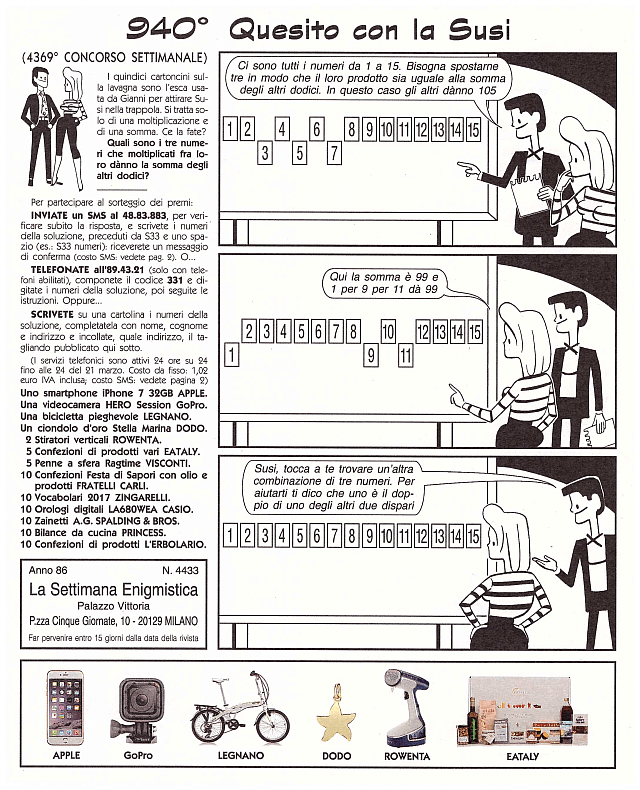

## Bisogna trovare la terna di valori che:
- devono essere diversi e compresi in [1,15]
- il loro prodotto == alla somma degli altri 12
- A è pari, B e C sono dispari
- A == 2*B

### Primo approccio: brute-force generation and test
- genero tutte le combinazioni
- controllo i vincoli

In [14]:
def trova_soluzione():
    for A in range(1,16):
        for B in range(1,16):
            for C in range(1,16):
                if A != B != C:
                    if A%2 == 0 and B*2 == A:
                        somma = sum(range(1,16))-A-B-C
                        prodotto = A*B*C
                        if somma == prodotto:
                            return A,B,C
%timeit trova_soluzione()



166 μs ± 628 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


### Questo è un po' inefficiente
- **prima** genero tutte le 15 * 15 * 15=3375 combinazioni
- **poi** le filtro

Conviene sfruttare i vincoli in modo da generare meno combinazioni
- A può essere solo pari (7 possibilità)
- B è la metà di A (1 possibilità)
- C deve essere dispari (8 possibilità)

In totale esaminaimo solo 7*8=56 casi

- prendo un valore A **pari** tra 1 e 15
  - prendo B = A//2
    - prendo C dispari tra 1 e 15 diverso da B
      - se A*B*C == somma degli altri
        - stampo A,B,C
       
NOTA: la somma di tutti i 15 valori -A-B-C è la somma dei rimanenti

In [15]:
def susi_940():
    SOMMA = sum(range(1,16))       # oppure (1+15)*15//2=120
    for A in range(2,15,4):        # scandisco i pari tra 1 e 15 non multipli di 4
        B = A//2                   # in modo che B sia dispari
        for C in range(1,16,2):    # scandisco i dispari tra 1 e 15
            if C == B: continue    # se C == B lo ignoro
            if A*B*C == SOMMA -A-B-C :
                return A,B,C
%timeit susi_940()

1.65 μs ± 3.22 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


# Proviamo con Wolfram Alpha

![](alpha-query.png)

![](alpha-answer.png)

## Più in generale, per trovare TUTTE le terne in una sequenza 1..N
(anche quelle che non sono pari dispari dispari)

Facciamo in modo che siano $A<B<C$ 
- per ciascun valore $A \in [1..N-2]$ (devo fermarmi al terzultimo)
  - per ciascun valore $B \in (A..N-1]$ (devo fermarmi al penultimo)
    - per ciascun valore $C \in (B..N]$
      - se $A*B*C = SOMMA-A-B-C$
        - stampo A, B, C

In [16]:
def susi_940_generale(N, verbose=True):
    quanti = 0
    SOMMA = sum(range(1,N+1))        # vale anche (N+1)*N//2
    for A in range(1,N-1):           # devo fermarmi al terzultimo (limite N-2)
        for B in range(A+1,N):       # devo fermarmi al penultimo  (limite N-1)
            for C in range(B+1,N+1): # devo arrivare ad N
                if A*B*C == SOMMA-A-B-C:
                    if verbose : print(A,B,C) 
                    quanti += 1
    return quanti

susi_940_generale(15)

1 7 14
1 9 11
3 5 7


3

In [17]:
for i in range(1,100):
    if susi_940_generale(i, verbose=False) == 3:
        print(i, end=' ', flush=True)

15 20 24 29 30 31 42 44 54 55 59 71 72 73 74 76 88 90 97 

# Altri tipi di file: [JSON](https://docs.python.org/3/library/json.html)
File di testo con sintassi semplificata per rappresentare:
- dizionari
- liste
- interi, stringhe, float, bool, None

Molto usati nelle applicazioni WEB

In [18]:
## Esempio
import json

with open('api.github.com.json') as F:
    api = json.load(F)
!cat api.github.com.json
api

{
  "current_user_url": "https://api.github.com/user",
  "current_user_authorizations_html_url": "https://github.com/settings/connections/applications{/client_id}",
  "authorizations_url": "https://api.github.com/authorizations",
  "code_search_url": "https://api.github.com/search/code?q={query}{&page,per_page,sort,order}",
  "commit_search_url": "https://api.github.com/search/commits?q={query}{&page,per_page,sort,order}",
  "emails_url": "https://api.github.com/user/emails",
  "emojis_url": "https://api.github.com/emojis",
  "events_url": "https://api.github.com/events",
  "feeds_url": "https://api.github.com/feeds",
  "followers_url": "https://api.github.com/user/followers",
  "following_url": "https://api.github.com/user/following{/target}",
  "gists_url": "https://api.github.com/gists{/gist_id}",
  "hub_url": "https://api.github.com/hub",
  "issue_search_url": "https://api.github.com/search/issues?q={query}{&page,per_page,sort,order}",
  "issues_url": "https://api.github.com/issues

{'current_user_url': 'https://api.github.com/user',
 'current_user_authorizations_html_url': 'https://github.com/settings/connections/applications{/client_id}',
 'authorizations_url': 'https://api.github.com/authorizations',
 'code_search_url': 'https://api.github.com/search/code?q={query}{&page,per_page,sort,order}',
 'commit_search_url': 'https://api.github.com/search/commits?q={query}{&page,per_page,sort,order}',
 'emails_url': 'https://api.github.com/user/emails',
 'emojis_url': 'https://api.github.com/emojis',
 'events_url': 'https://api.github.com/events',
 'feeds_url': 'https://api.github.com/feeds',
 'followers_url': 'https://api.github.com/user/followers',
 'following_url': 'https://api.github.com/user/following{/target}',
 'gists_url': 'https://api.github.com/gists{/gist_id}',
 'hub_url': 'https://api.github.com/hub',
 'issue_search_url': 'https://api.github.com/search/issues?q={query}{&page,per_page,sort,order}',
 'issues_url': 'https://api.github.com/issues',
 'keys_url': '

## Attenzione:
- **NO COMMENT:** non si possono inserire commenti
- **NO ENDING COMMA:** non si può aggiungere una virgola in fondo a lista o dizionario
- **SOLO chiavi semplici** (NO tuple, SI int, float, str, none, bool)
- **SOLO doppi apici** **`"`** (NO singoli apici)
- **NO TUPLE:** si possono usare liste e poi convertirle 

## Abbastanza facili da usare in python
Conversione automatica per alcuni tipi di dati
- **`json.load(<file>) -> dict | list | tipo_base`**
- **`json.dump(<obj>, <file>)`**

Personalizzabile anche per altri tipi di oggetti (non ovvio, per casa per chi è interessato)

In [19]:
# posso anche leggere da una stringa in formato JSON con la funzione 'loads'
XX = json.loads('''
[{"nome": "Minnie", "cognome": "Mouse", "telefono": "555-54321", 
  "indirizzo": "via di M.me Curie 1", "città": "Topolinia"}, 
{"nome": "Pippo", "cognome": "de' Pippis", "telefono": "555-33333", 
 "indirizzo": "via dei Pioppi 1", "città": "Topolinia"}]
''')
XX

[{'nome': 'Minnie',
  'cognome': 'Mouse',
  'telefono': '555-54321',
  'indirizzo': 'via di M.me Curie 1',
  'città': 'Topolinia'},
 {'nome': 'Pippo',
  'cognome': "de' Pippis",
  'telefono': '555-33333',
  'indirizzo': 'via dei Pioppi 1',
  'città': 'Topolinia'}]

In [20]:
# oppure produrre la stringa in formato JSON da una struttura Python
print(json.dumps(XX, indent=4))

[
    {
        "nome": "Minnie",
        "cognome": "Mouse",
        "telefono": "555-54321",
        "indirizzo": "via di M.me Curie 1",
        "citt\u00e0": "Topolinia"
    },
    {
        "nome": "Pippo",
        "cognome": "de' Pippis",
        "telefono": "555-33333",
        "indirizzo": "via dei Pioppi 1",
        "citt\u00e0": "Topolinia"
    }
]


In [21]:
# Un file json può contenere valori semplici (int, float, str, True=true, False=false, None=null)
print(json.dumps(None))

print(json.dumps([False, True]))

## NOTA: le stringhe nel file json sono racchiuse SOLO da doppi apici
print(json.dumps('Pape"rino'))

null
[false, true]
"Pape\"rino"


In [22]:
# Esempio: data una tabella come lista di dizionari
agenda = [
    {'nome': 'Paperino','cognome':'Paolino',      'telefono':'555-1313',  'indirizzo': 'via dei Peri 113',          'città': 'Paperopoli'},
    {'nome': 'Gastone', 'cognome':'Paperone',     'telefono':'555-1717',  'indirizzo': 'via dei Baobab 42',         'città': 'Paperopoli'},
    {'nome': 'Paperon', 'cognome':"de' Paperoni", 'telefono':'555-99999', 'indirizzo': 'colle Papero 1',            'città': 'Paperopoli'},
    {'nome': 'Archimede','cognome':'Pitagorico',  'telefono':'555-11235', 'indirizzo': 'colle degli Inventori 1',   'città': 'Paperopoli'},
    {'nome': 'Pietro',  'cognome':'Gambadilegno', 'telefono':'555-66666', 'indirizzo': 'via dei Ladri 13',          'città': 'Topolinia'},
    {'nome': 'Trudy',   'cognome':'Gambadilegno', 'telefono':'555-66666', 'indirizzo': 'via dei Ladri 13',          'città': 'Topolinia'},
    {'nome': 'Topolino','cognome':'Mouse',        'telefono':'555-12345', 'indirizzo': 'via degli Investigatori 1', 'città': 'Topolinia'},
    {'nome': 'Minnie',  'cognome':'Mouse',        'telefono':'555-54321', 'indirizzo': 'via di M.me Curie 1',       'città': 'Topolinia'},
    {'nome': 'Pippo',   'cognome':"de' Pippis",   'telefono':'555-33333', 'indirizzo': 'via dei Pioppi 1',          'città': 'Topolinia'},
    ]

In [23]:
import json
# prima la salvo nel file
with open('agenda.json', encoding='utf8', mode='w') as F:
    json.dump(agenda, F, indent=4)
    
!cat agenda.json

[
    {
        "nome": "Paperino",
        "cognome": "Paolino",
        "telefono": "555-1313",
        "indirizzo": "via dei Peri 113",
        "citt\u00e0": "Paperopoli"
    },
    {
        "nome": "Gastone",
        "cognome": "Paperone",
        "telefono": "555-1717",
        "indirizzo": "via dei Baobab 42",
        "citt\u00e0": "Paperopoli"
    },
    {
        "nome": "Paperon",
        "cognome": "de' Paperoni",
        "telefono": "555-99999",
        "indirizzo": "colle Papero 1",
        "citt\u00e0": "Paperopoli"
    },
    {
        "nome": "Archimede",
        "cognome": "Pitagorico",
        "telefono": "555-11235",
        "indirizzo": "colle degli Inventori 1",
        "citt\u00e0": "Paperopoli"
    },
    {
        "nome": "Pietro",
        "cognome": "Gambadilegno",
        "telefono": "555-66666",
        "indirizzo": "via dei Ladri 13",
        "citt\u00e0": "Topolinia"
    },
    {
        "nome": "Trudy",
        "cognome": "Gambadilegno",
        "telefono"

In [24]:
# poi la ricarico
with open('agenda.json', encoding='utf8') as F:
    L1 = json.load(F)
L1[:2]  # e ne mostro i primi 2 elementi

[{'nome': 'Paperino',
  'cognome': 'Paolino',
  'telefono': '555-1313',
  'indirizzo': 'via dei Peri 113',
  'città': 'Paperopoli'},
 {'nome': 'Gastone',
  'cognome': 'Paperone',
  'telefono': '555-1717',
  'indirizzo': 'via dei Baobab 42',
  'città': 'Paperopoli'}]

# File [YAML](https://pyyaml.org/wiki/PyYAMLDocumentation) (un altro modo di rappresentare dati annidati come testo semplice)
- dizionari (una **chiave `:` valore** per ciascuna riga)
- liste  ( valori su righe diverse, preceduti da **`-`**)
- dati semplici (str senza apici se possibile, True, False, null=None, interi, float)
- documenti multipli
- generici oggetti Python (advanced)

Per annidare le strutture si usa l'**indentazione**

In [25]:
import yaml
with open('agenda.yaml', mode='w', encoding='utf8') as F:
    yaml.dump(agenda[:2], F) # ci metto gli ultimi 2 elementi
!cat agenda.yaml

- "citt\xE0": Paperopoli
  cognome: Paolino
  indirizzo: via dei Peri 113
  nome: Paperino
  telefono: 555-1313
- "citt\xE0": Paperopoli
  cognome: Paperone
  indirizzo: via dei Baobab 42
  nome: Gastone
  telefono: 555-1717


## leggere/scrivere file YAML
- **`yaml.dump(<oggetto>, FILE)`**  salva l'oggetto nel file (che deve essere stato già aperto con open)
- **`yaml.safe_load(FILE) -> <oggetto>`** legge l'oggetto dal file (che deve essere stato già aperto con open)
  - legge il contenuto di un file
  - oppure una stringa

In [26]:
## posso decodificare direttamente del testo con yaml.safe_load
testo = """
  none: [~, null]
  bool: [true, false, on, off]
  int: 42
  float: 3.14159
  list: 
    - LITE 
    - RES_ACID 
    - SUS_DEXT
  dict:
    hp: 13 
    sp: 5
"""
yaml.safe_load(testo)

{'none': [None, None],
 'bool': [True, False, True, False],
 'int': 42,
 'float': 3.14159,
 'list': ['LITE', 'RES_ACID', 'SUS_DEXT'],
 'dict': {'hp': 13, 'sp': 5}}

In [27]:
with open('esempio.yaml', mode='w', encoding='utf8') as F:
    print(testo, file=F)

!cat esempio.yaml
# oppure leggerlo direttamente da file
with open('esempio.yaml') as F:
    EX = yaml.safe_load(F)
EX


  none: [~, null]
  bool: [true, false, on, off]
  int: 42
  float: 3.14159
  list: 
    - LITE 
    - RES_ACID 
    - SUS_DEXT
  dict:
    hp: 13 
    sp: 5



{'none': [None, None],
 'bool': [True, False, True, False],
 'int': 42,
 'float': 3.14159,
 'list': ['LITE', 'RES_ACID', 'SUS_DEXT'],
 'dict': {'hp': 13, 'sp': 5}}

# Leggere pagine o file da Internet
Ci sono molte librerie, la più comune è <b>[requests](https://requests.readthedocs.io/en/latest/user/quickstart/)</b>
- permette di eseguire richieste sia di tipo **GET** che **POST**
  - **GET** classico url che inserite nel browser, volendo con parametri codificati direttamente nell'URL
  - **POST** richiesta che una form html fa al server, con tutti i contenuti dei campi della form
- con parametri
- torna un codice di errore/OK
- e decodifica il testo della pagina html o json

Molto potente, permette anche streaming, sessioni, ...

In [28]:
# importo la libreria
import requests

# leggo la pagina di python.org
pagina = requests.get('https://python.org')

# lo status code ci dice se tutto è andato bene
status = pagina.status_code

# se è un testo nell'attributo text trovo il testo decodificato
contenuto = pagina.text

print('status:\t\t', status, '\nencoding:\t', pagina.encoding,'\n', contenuto[:500])

status:		 200 
encoding:	 utf-8 
 <!doctype html>
<!--[if lt IE 7]>   <html class="no-js ie6 lt-ie7 lt-ie8 lt-ie9">   <![endif]-->
<!--[if IE 7]>      <html class="no-js ie7 lt-ie8 lt-ie9">          <![endif]-->
<!--[if IE 8]>      <html class="no-js ie8 lt-ie9">                 <![endif]-->
<!--[if gt IE 8]><!--><html class="no-js" lang="en" dir="ltr">  <!--<![endif]-->

<head>
    <script defer data-domain="python.org" src="https://analytics.python.org/js/script.outbound-links.js"></script>

    <meta charset="utf-8">
    <met


## le pagine JSON vengono automaticamente decodificate

In [29]:
# leggo da internet una pagina JSON
pagina_json = requests.get('https://api.github.com')

# la decodifica avviene automaticamente col metodo json()
risultato = pagina_json.json()
risultato

{'current_user_url': 'https://api.github.com/user',
 'current_user_authorizations_html_url': 'https://github.com/settings/connections/applications{/client_id}',
 'authorizations_url': 'https://api.github.com/authorizations',
 'code_search_url': 'https://api.github.com/search/code?q={query}{&page,per_page,sort,order}',
 'commit_search_url': 'https://api.github.com/search/commits?q={query}{&page,per_page,sort,order}',
 'emails_url': 'https://api.github.com/user/emails',
 'emojis_url': 'https://api.github.com/emojis',
 'events_url': 'https://api.github.com/events',
 'feeds_url': 'https://api.github.com/feeds',
 'followers_url': 'https://api.github.com/user/followers',
 'following_url': 'https://api.github.com/user/following{/target}',
 'gists_url': 'https://api.github.com/gists{/gist_id}',
 'hub_url': 'https://api.github.com/hub',
 'issue_search_url': 'https://api.github.com/search/issues?q={query}{&page,per_page,sort,order}',
 'issues_url': 'https://api.github.com/issues',
 'keys_url': '

## Scaricare file binari
- il contenuto "raw" (crudo) è nell'attributo **`content`** della risposta

In [30]:
## possiamo anche scaricare file binari
logo = requests.get('https://www.python.org/static/img/python-logo.png')

# posso estrarre dagli headers le dimensioni in bytes e il tipo del file ()
print(logo.headers['Content-Length'], logo.headers['Content-Type'], logo.status_code)

15770 image/png 200


In [31]:
# se si tratta di un file di dati (immagine/audio/film ...) 
# il contenuto lo trovo nell'attributo content
dati = logo.content

# per salvarlo posso aprire un file in scrittura ('w') e in modo binario ('b')
with open('logo.png', mode='wb') as F:
    F.write(dati)

In [32]:
!ls -alh 'logo.png'
print(dati[:100])

-rw-r--r--  1 andrea  staff    15K Nov  4 21:15 logo.png
b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x02D\x00\x00\x00\xa4\x08\x06\x00\x00\x00v;1\xf1\x00\x00\x00\tpHYs\x00\x00\x0b\x13\x00\x00\x0b\x13\x01\x00\x9a\x9c\x18\x00\x00 \x00IDATx\x9c\xed\x9dy\x9c\x1ce\x9d\xff?\xdf\xaa\x9eL\x8e\xc91\xb9\xc8\x1c9\x80If2\xe6 $\x18\x02\x01"+\xcb\x8d\xbb\xca'


Ed ecco il risultato

![](logo.png)

### Per mostrare l'immagine in Jupyter senza salvare il file
basta fornire i dati binari alla classe **IPython.display.Image**

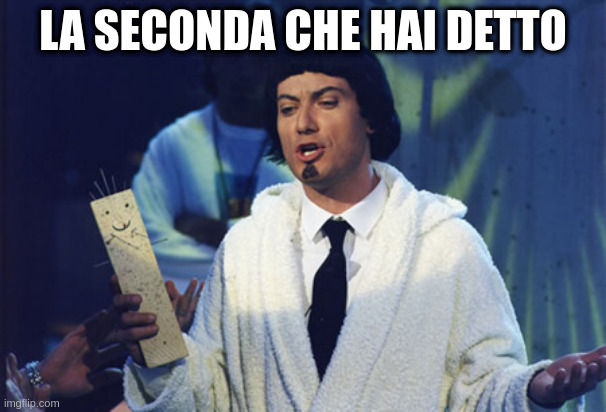

In [33]:
from IPython.display import Image
dati = requests.get('https://i.imgflip.com/5vcovc.jpg').content
Image(dati)

## Passare parametri ad una GET
Si usa l'argomento **`params`** (un dizionario)
- **`parametri={ chiave: valore, ...}`**
- **`requests.get( <URL>, params=parametri )`**

In [34]:
# Search Google for the requests Python library
response = requests.get(
    'https://google.com',
    params={'q': 'python requests'},
)
print(response.text[:1000])

<!doctype html><html itemscope="" itemtype="http://schema.org/WebPage" lang="it"><head><meta content="text/html; charset=UTF-8" http-equiv="Content-Type"><meta content="/images/branding/googleg/1x/googleg_standard_color_128dp.png" itemprop="image"><title>Google</title><script nonce="ihW2xTvjt8EgYiES_vVNMw">(function(){var _g={kEI:'1F4KaZDKLvTq1e8PuPWw6QY',kEXPI:'0,4149912,90133,94918,344796,247320,5285339,19,36811690,25228681,152387,65159,30635,9140,4598,328,6226,63456,709,15048,8215,119084,1258,352,18880,7876,5708,5774,8976,6052,12583,4719,837,10968,12533,10657,12107,5683,3605,37051,10886,2,276,4708,936,5089,1,9630,1033,6096,10083,2747,2,4,1,320,844,347,2901,1011,667,10712,1573,732,687,3348,10588,5706,407,183,4,1378,136,3355,767,748,2115,826,1554,2,1347,688,3964,16,4429,604,4874,4384,2,3105,4496,593,19,539,2468,27,769,4072,1524,3557,632,238,640,2135,1264,2,981,6,4503,2158,1542,1400,425,7289,1384,1840,202,41,788,243,6,1,1302,674,3111,845,2047,1,1,9,14,421,14,72,1053,1708,1126,9,27,8,21

## Passare parametri ad altri metodi HTTP
Si usa l'argomento **`data=<dizionario>`** che contiene i parametri
```python
requests.post(   'https://httpbin.org/post',   data={'key':'value'})
requests.put(    'https://httpbin.org/put',    data={'key':'value'})
requests.delete( 'https://httpbin.org/delete')
requests.head(   'https://httpbin.org/get')
requests.patch(  'https://httpbin.org/patch',  data={'key':'value'})
requests.options('https://httpbin.org/get')
```

# PAUSA

# Le Immagini

![](Rgb-raster-image.svg.png)

- sono griglie rettangolari di pixel (**pic**ture **el**ement) colorati 
- ogni posizione a coordinate x,y contiene un colore
- **[RGB](https://en.wikipedia.org/wiki/RGB_color_model)** è un modo di codificare i colori
  (altri [Color spaces](https://en.wikipedia.org/wiki/Color_space): HSV/L/B, CMYK)
  - R: luminosità della componente rossa (red)
  - G: luminosità della componente verde (green)
  - B: luminosità della componente blu   (blue)

Questi valori in genere sono codificati in un byte ciascuno [0 .. 255] quindi un pixel occupa 3*8=24 bit (16M colori)

In [35]:
# %load_ext nb_mypy

In [36]:
Pixel   = tuple[int,int,int]
# con valori tra 0 e 255 compresi (1 byte)
# definiamo qualche colore
black : Pixel =   0,   0,   0    # luminosità minime
white : Pixel = 255, 255, 255    # luminosità massime
red   : Pixel = 255,   0,   0
green : Pixel =   0, 255,   0
blue  : Pixel =   0,   0, 255
cyan  : Pixel =   0, 255, 255
yellow: Pixel = 255, 255,   0
purple: Pixel = 255,   0, 255
grey  : Pixel = 128, 128, 128

## Immagine = matrice di pixel = lista di liste di triple
- per semplicità usiamo una **lista di liste**
- la **lista esterna** è l'immagine, che contiene **righe orizzontali di pixel**
- ciascuna **riga** di pixel è una **lista di pixel**
- ciascun **pixel** è rappresentato da una terna **(R, G, B)** con valori interi tra [0..255]
- <u>tutte le righe hanno la stessa lunghezza</u>
- le righe nella immagine sono disposte dall'alto in basso (l'asse Y va in giù)
- ciascuna riga va da sinistra a destra (l'asse X va verso destra)

**NOTA:** Le immagini definite così sono una scusa per farvi manipolare matrici. Per manipolare immagini davvero si usa la libreria **[Pillow](https://pillow.readthedocs.io/)** che non useremo nel corso.

In [6]:
import images
# esempio di bandiera    rossa bianca verde
img = [
        [(0,0,0), (0,0,0), (0,0,0), (0,0,0), (0,0,0), (0,0,0), (0,0,0), (0,0,0), (0,0,0) ],
        [(0,0,0), (255,0,0), (255,0,0), (255,255,255), (255,255,255), (255,255,255), (0,255,0), (0,255,0), (0,255,0) ],
        [(0,0,0), (255,0,0), (255,0,0), (255,255,255), (255,255,255), (255,255,255), (0,255,0), (0,255,0), (0,255,0) ],
        [(0,0,0), (255,0,0), (255,0,0), (255,255,255), (255,255,255), (255,255,255), (0,255,0), (0,255,0), (0,255,0) ],
        [(0,0,0), (255,0,0), (255,0,0), (255,255,255), (255,255,255), (255,255,255), (0,255,0), (0,255,0), (0,255,0) ],
        [(0,0,0), (255,0,0), (255,0,0), (255,255,255), (255,255,255), (255,255,255), (0,255,0), (0,255,0), (0,255,0) ],
        [(0,0,0), (255,0,0), (255,0,0), (255,255,255), (255,255,255), (255,255,255), (0,255,0), (0,255,0), (0,255,0) ],
        [(0,0,0), (255,0,0), (255,0,0), (255,255,255), (255,255,255), (255,255,255), (0,255,0), (0,255,0), (0,255,0) ],
        [(0,0,0), (255,0,0), (255,0,0), (255,255,255), (255,255,255), (255,255,255), (0,255,0), (0,255,0), (0,255,0) ],
        [(0,0,0), (255,0,0), (255,0,0), (255,255,255), (255,255,255), (255,255,255), (0,255,0), (0,255,0), (0,255,0) ],
        [(0,0,0), (255,0,0), (255,0,0), (255,255,255), (255,255,255), (255,255,255), (0,255,0), (0,255,0), (0,255,0) ],
      ]

images.visd(img)

## Come trovare un pixel

Se **img** contiene la lista di righe

**img[y]** è la riga **y** esima (partendo dall'alto)

**img[y][x]** è il pixel della riga **y** che si trova a colonna **x** (da sinistra a destra)

# Creiamo di una immagine/matrice monocolore !!! MA nel modo sbagliato !!!

In [38]:
Line    = list[Pixel]
Picture = list[Line]

def crea_immagine_errata(larghezza : int, altezza : int, colore : Pixel) -> Picture :
    riga = [ colore ] * larghezza     # creo una lista di pixel
    img  = [ riga   ] * altezza       # creo una lista di righe
    return img

In [39]:
img2 : Picture = crea_immagine_errata(30, 40, blue)

# img2[5][7] = red     # Provo a colorare un solo pixel

images.visd(img2)    # e trovo una colonna rossa!!!

## PERCHE' viene una riga verticale invece che un punto?

L'istruzione **`riga = [ colore ] * larghezza`**  costruisce una <u>lista di RIFERIMENTI </u>ad un **unico** colore in memoria

Ciascuna posizione della lista/riga indica la stessa unica tripla RGB

In [40]:
# figura di una lista di riferimenti allo stesso colore
from pygraphviz import AGraph
G = AGraph(rankdir='TD', directed=True)
for N in range(10):
    if N:
        G.add_edge(N-1, N, size=0, color='white')
    G.add_edge(N, "(0,0,0)\nblack")
G.add_subgraph(list(range(10)), rank="same")
G.layout('dot')

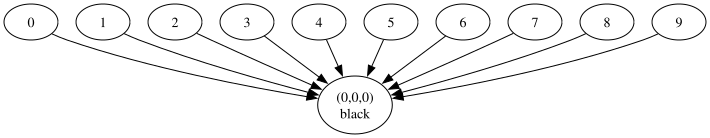

In [41]:
G

L'istruzione **`img = [ riga ] * altezza`**  costruisce una lista di RIFERIMENTI <u>ad una unica riga</u> in memoria

In [42]:
# figura di una lista di riferimenti alla stessa lista
G = AGraph(rankdir='LR', directed=True)
for N in range(5):
    if N:
        G.add_edge(N-1, N, size=0, color='white')
    G.add_edge(N, "[ la riga di pixel creata prima ]")
G.add_subgraph(list(range(5)), rank="same")
G.layout('dot')

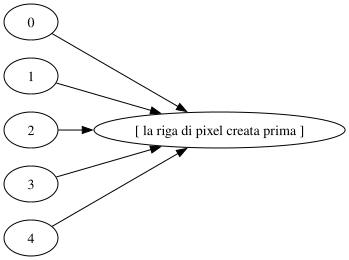

In [43]:
G

Mentre **la prima istruzione va bene** perchè tutti i colori sono tuple, **immutabili**

**La seconda NON VA BENE** perchè vogliamo che le righe siano **modificabili indipendentemente** l'una dall'altra

## Creiamo l'immagine nel modo giusto

In [44]:
def crea_immagine(larghezza : int, altezza : int, colore : Pixel=black) -> Picture:
    "costruzione di una immagine con una list-comprehension"
    return [  [ colore ]*larghezza            # creo una nuova riga di pixel 'colore'
                    for _ in range(altezza)   # e lo faccio 'altezza' volte indipendentemente
           ]

def crea_imm(larghezza : int, altezza : int, colore: Pixel=black) -> Picture:
    "qui faccio lo stesso ma senza list-comprehension"
    img = []                          # immagine = lista di righe inizialmente vuota
    for y in range(altezza):          # per altezza volte
        riga = []                     # creo una riga = lista di pixel inizialmente vuota
        for x in range(larghezza):    # e per larghezza volte
            riga.append(colore)       # aggiungo il pixel alla riga corrente
        img.append(riga)              # e poi aggiungo la riga all'immagine
    return img                        # torno la lista di liste finale

In [45]:
img = crea_immagine(30, 40, red)
img[5][7] = blue     # coloro un pixel

images.visd(img)     # e ora va molto meglio, si colora un solo punto

# Come caricare/salvare una immagine da/su disco

183 275


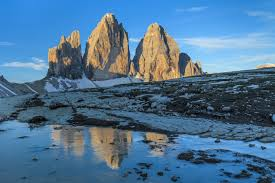

In [46]:
# images.load(filename : str) -> Picture
import images
img3 = images.load('3cime.png')

print(len(img3), len(img3[0]))   # altezza e larghezza
images.visd(img3)                # visualizza la Picture in Jupyter

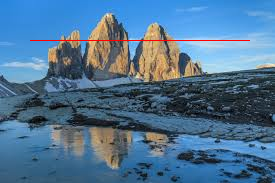

In [47]:
img3[40][30:250] = [red]*220     # coloriamo una fila orizzontale di pixel usando le slice
                                 # ATTENZIONE: il numero di pixel deve essere quello giusto
# images.save(img : Picture, filename : str) -> None
images.save(img3, '3cime-2.png')

images.visd(img3)

# Disegnare un pixel a coordinate qualsiasi
**MA ... senza generare errori se le coordinate sono fuori dall'immagine**

In [48]:
# Opzione 1 --- controllando le posizioni
def draw_pixel(img : Picture, x : int|float, y : int|float, colore : Pixel):
    # ricavo l'altezza e larghezza dell'immagine contando righe e colonne
    A,L = len(img), len(img[0])
    x = int(round(x))       # voglio gestire anche coordinate float
    y = int(round(y))
    # cambio il pixel solo se è dentro l'immagine
    if 0 <= x < L and 0 <= y < A:
        img[y][x] = colore       # nella riga y e nella colonna x metto il colore

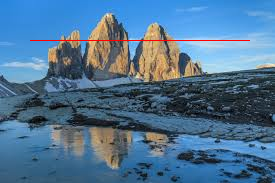

In [49]:
# Riprendo l'esempio
draw_pixel(img3, 20, 2000, red)

images.visd(img3)

# Gestione degli errori con **Try/except/finally**

Per catturare eventuali errori e gestirli nel proprio programma si usa
```python
try:
    codice che potrebbe produrre un errore
except TipoDiErrore as e:
    codice da eseguire se TipoDiErrore
except AltroTipo:
    ...
finally:
    codice da eseguire alla fine SEMPRE
```

**NOTA:** la clausola **except:** che da sola cattura TUTTE le eccezioni **E' FORTEMENTE SCONSIGLIATA** 
perchè potrebbe nascondere degli errori che non vi aspettate e che vanno gestiti diversamente

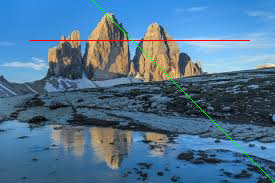

In [50]:
# Secondo modo: --- usando try-except per catturare l'errore di sbordamento?
def draw_pixel_wrong(img : Picture, x : int, y : int, colore : Pixel):
    # mi preparo a catturare l'errore (try)
    try:
        img[y][x] = colore         # provo a disegnare il pixel a coordinate x,y
    except IndexError:
        pass                       # se c'è errore di index nelle liste lo ignoro

# --- BEWARE of negative indexes!!! (che non producono errori ma lavorano a ritroso nelle liste)

# --- BEWARE of generic 'catch-all' except clauses!!!!! (che nascondono TROPPI errori)

for i in range(-1000,0):
    draw_pixel_wrong(img3, i, i, green)   # disegno fuori in alto a sinistra
images.visd(img3)

coordinate FUORI -20,-20
coordinate FUORI -19,-19
coordinate FUORI -18,-18
coordinate FUORI -17,-17
coordinate FUORI -16,-16
coordinate FUORI -15,-15
coordinate FUORI -14,-14
coordinate FUORI -13,-13
coordinate FUORI -12,-12
coordinate FUORI -11,-11
coordinate FUORI -10,-10
coordinate FUORI -9,-9
coordinate FUORI -8,-8
coordinate FUORI -7,-7
coordinate FUORI -6,-6
coordinate FUORI -5,-5
coordinate FUORI -4,-4
coordinate FUORI -3,-3
coordinate FUORI -2,-2
coordinate FUORI -1,-1


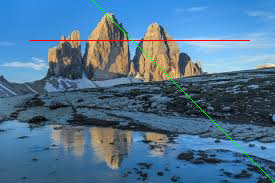

In [51]:
def draw_pixel_maybe_better(img : Picture, x : int|float, y : int|float, colore : Pixel):
    x = int(round(x))       # voglio gestire anche coordinate float
    y = int(round(y))
    A,L = len(img), len(img[0])
    # mi preparo a catturare l'errore (try)
    try:
        # controllo le coordinate e lancio un errore se sbordo
        assert 0 <= x < L and 0 <= y < A , f"coordinate FUORI {x},{y}"
        img[y][x] = colore         # disegno il pixel
    except AssertionError as e:    # se l'asserzione era falsa ho sbordato dall'immagine
        print(e)                   # stampo l'eccezione
        pass

# MA questo è lo stesso che usare un if!!! NON NE VALE LA PENA
for i in range(-20,0):
    draw_pixel_maybe_better(img3, i, i, red)

images.visd(img3)

# Rotazione di 90° a sinistra (antioraria)
![](rotazione.png)

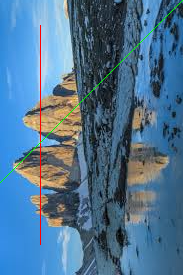

In [52]:
# X_destinazione = y_sorgente
# Y_destinazione = larghezza_sorgente - 1 - x_sorgente

def ruota_sx(img):
    altezza, larghezza = len(img),len(img[0])     # ottengo le dimensioni
    img2 = crea_immagine(altezza, larghezza)      # creo una immagine nera con altezza e larghezza scambiate
    for y, riga in enumerate(img):                # per ogni pixel della immagine originale
        for x, pixel in enumerate(riga):
            XD = y                                 # calcolo le coordinate XD,YD della destinazione
            YD = larghezza -1 -x
            img2[YD][XD] = pixel                    # e copio il pixel nella destinazione
    return img2                                   # torno l'immagine ruotata

def ruota_sx2(img):
    altezza, larghezza = len(img),len(img[0])     # ottengo le dimensioni
    img2 = crea_immagine(altezza, larghezza)      # creo una immagine nera con altezza e larghezza scambiate
    for y in range(altezza):
        for x in range(larghezza):    
            XD = y                                # calcolo le coordinate XD,YD della destinazione
            YD = larghezza -1 -x
            img2[YD][XD] = img[y][x]              # e copio il pixel nella destinazione
    return img2                                   # torno l'immagine ruotata




img_r = ruota_sx2(img3)

images.visd(img_r)

# --- PER CASA: rotazione destra

# Disegnare una linea orizzontale o verticale

CPU times: user 40 μs, sys: 0 ns, total: 40 μs
Wall time: 42.2 μs
CPU times: user 8 μs, sys: 0 ns, total: 8 μs
Wall time: 9.06 μs


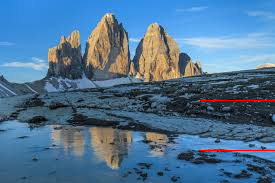

In [53]:
def draw_h_line(img, x, y, x2, colore):
    altezza   = len(img)
    if 0 <= y < altezza:                   # SOLO se la y è tra 0 e altezza
        if x>x2 : x, x2 = x2, x            # scambio i valori se non sono nell'ordine giusto
        for X in range(x, x2+1):           # scandisco le X da x a x2
            draw_pixel(img, X, y, colore)  # riusiamo la draw_pixel che controlla di non sbordare

# oppure prima intersechiamo la linea con l'immagine e poi la disegnamo senza controllare
def draw_h_line2(img, x, y, x2, colore):
    altezza   = len(img)
    if 0 <= y < altezza:                   # SOLO se la y è tra 0 e altezza
        if x>x2 : x, x2 = x2, x            # scambio i valori se non sono nell'ordine giusto
        larghezza = len(img[0])
        # la parte da disegnare ha estremi non maggiori di larghezza-1 e non minori di 0
        xmin = min(max(x, 0), larghezza-1)
        xmax = max(min(x2, larghezza-1),0)
        # una volta aggiustati gli estremi la si disegna SENZA CONTROLLI!
        img[y][xmin:xmax+1] = [colore]*(xmax-xmin+1)    # con un assegnamento a slice
           
img = images.load('3cime.png')
%time draw_h_line( img, 300, 100, 200, red)    # x>x2       
%time draw_h_line2(img, 300, 150, 200, red)    # x>x2       questa è più rapida

images.visd(img)

In [54]:
# lo stesso per una linea verticale
def draw_v_line(img, x, y, y2, colore):
    larghezza = len(img[0])
    if 0 <= x < larghezza:               # SOLO se la x è tra 0 e larghezza
        if y>y2 : y, y2 = y2, y          # scambio i valori se non sono nell'ordine giusto
        for Y in range(y, y2+1):
            # riusiamo la draw_pixel che controlla di non sbordare
            draw_pixel(img, x, Y, colore)

# oppure prima intersechiamo la linea con l'immagine e poi la disegnamo senza controllare
def draw_v_line2(img, x, y, y2, colore):
    larghezza = len(img[0])
    if 0 <= x < larghezza:               # SOLO se la x è tra 0 e larghezza
        if y>y2 : y, y2 = y2, y          # scambio i valori se non sono nell'ordine giusto
        altezza   = len(img)
        # la parte da disegnare ha estremi non maggiori di altezza-1 e non minori di 0
        ymin = min(max(y, 0), altezza-1)
        ymax = max(min(y2, altezza-1),0)
        # una volta aggiustati gli estremi la si disegna SENZA CONTROLLI!
        for Y in range(ymin, ymax+1):    # qui è necessario fare un ciclo
            img[Y][x] = colore

CPU times: user 56 μs, sys: 4 μs, total: 60 μs
Wall time: 60.8 μs
CPU times: user 12 μs, sys: 0 ns, total: 12 μs
Wall time: 11.9 μs


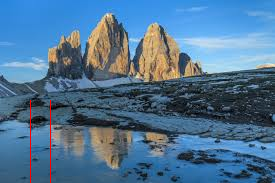

In [55]:
img = images.load('3cime.png')
%time draw_v_line( img, 50, 100, 200, red)            
%time draw_v_line2(img, 30, 100, 200, red)       # più rapida     

images.visd(img)

# E per le diagonali?

![](Bresenham.png)

Conviene scandire il cateto **più lungo** in modo che non ci siano colonne/righe senza pixel

In [56]:
# --- e diagonale??? come???
# dipende dalla direzione

def draw_slope(img, x1, y1, x2, y2, colore):
    dx = x2-x1
    dy = y2-y1

    # ci si sposta lungo la direzione più lunga
    # se |dx| > |dy| si calcola la y per ciascuna x in [x1 .. x2]
    if abs(dx) >= abs(dy):
        if x1 > x2 : x1, x2 = x2, x1             # mi assicuro che x1<x2
        m = dy/dx                                # calcolo il coefficiente angolare m=dy/dx 
        for x in range(x1, x2+1):                # e per ogni x in [x1 .. x2]
            y = m * (x - x1) + y1                # calcolo y = mx+c      con c=y1
            draw_pixel(img, x, y, colore)        # e disegno il pixel (con draw_pixel?)
    # altrimenti per ciascuna y calcoliamo la x
    else:            # semplicemente scambiando x e y nelle formule precedenti
        if y1 > y2 : y1, y2 = y2, y1             # mi assicuro che y1<y2
        m = dx/dy                                # calcolo m=dx/dy
        for y in range(y1, y2+1):                # e per ogni y in [y1 .. y2]
            x = m * (y - y1) + x1                # calcolo x = my+c      con c=y1
            draw_pixel(img, x, y, colore)        # e disegno il pixel (con draw_pixel?)

CPU times: user 117 μs, sys: 1e+03 ns, total: 118 μs
Wall time: 118 μs
CPU times: user 96 μs, sys: 1e+03 ns, total: 97 μs
Wall time: 96.3 μs
CPU times: user 58 μs, sys: 0 ns, total: 58 μs
Wall time: 59.8 μs


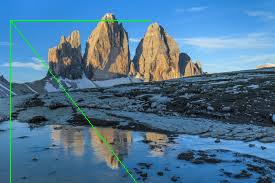

In [57]:
img = images.load('3cime.png')
%time draw_slope(img, 10,20, 150, 200, green)
%time draw_slope(img, 10,20, 10, 200, green)
%time draw_slope(img, 10,20, 150, 20, green)
images.visd(img)

# Disegnare un rettangolo vuoto

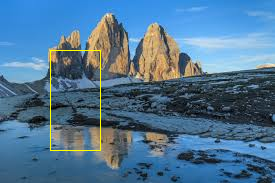

In [58]:
def draw_empty_rectangle(img,x1,y1,x2,y2,colore):
    # dobbiamo disegnare le 4 linee
    draw_h_line(img, x1, y1, x2, colore)
    draw_h_line(img, x1, y2, x2, colore)
    draw_v_line(img, x1, y1, y2, colore)
    draw_v_line(img, x2, y1, y2, colore)

def draw_empty_rectangle2(img,x1,y1,x2,y2,colore):
    for x in range(x1, x2+1):
        draw_pixel(img, x, y1, colore)
        draw_pixel(img, x, y2, colore)
    # oppure disegnare i pixel orizzontali
    # e poi i verticali
    for y in range(y1, y2+1):
        draw_pixel(img, x1, y, colore)
        draw_pixel(img, x2, y, colore)
    
img = images.load('3cime.png')
draw_empty_rectangle(img, 50, 50, 100, 150, yellow)

images.visd(img)

# Disegnare un rettangolo pieno

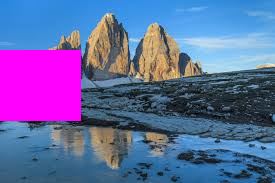

In [59]:
# questa è facile
def draw_rectangle(img, x1,y1, x2,y2, colore):
    for x in range(x1, x2+1):
        for y in range(y1, y2+1):
            draw_pixel(img, x,y, colore)

img = images.load('3cime.png')
draw_rectangle(img, -30,50, 80, 120, purple)

images.visd(img)

# Disegnare una ellisse
- una ellisse ha la proprietà che: **la somma delle distanze di ogni suo punto dai due fuochi è costante**

![](Ellipse-def-e.svg.png)

### QUINDI: i punti INTERNI hanno somma delle distanze MINORE di $2a$

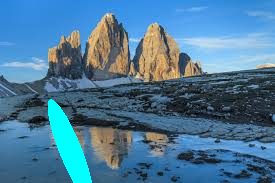

In [60]:
# disegnamo una ellisse PIENA colorando tutti i pixel
# --- con somma delle distanze dai fuochi <= D
from math import sqrt, dist

def draw_ellisse(img, x1, y1, x2, y2, D, colore):
    larghezza = len(img[0])
    altezza   = len(img)
    # scandisco tutti i pixel della immagine
    for x in range(larghezza):
        for y in range(altezza):
            # per ciascuno calcolo le due distanze dai fuochi
            D1 = dist((x,y), (x1,y1))
            D2 = dist((x,y), (x2,y2))
            # se la somma < D allora il pixel è DENTRO e lo coloro
            if D1+D2 < D:
                img[y][x] = colore
            # altrimenti lo ignoro

            # NOTA: non devo controllare se sono dentro l'immagine 
            # perchè scandisco SOLO i pixel della immagine

# NOTA: D deve essere più grande della distanza tra i due fuochi
# TODO: si possono scandire meno pixel invece che tutta l'immagine
        
img = images.load('3cime.png')
draw_ellisse(img, 50, 100, 90, 200, 110,  cyan)

images.visd(img)

### Se vogliamo solo il bordo $D1+D2-2a<1$

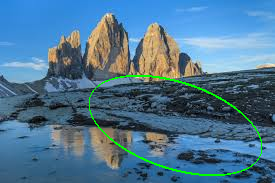

In [61]:
def draw_ellisse_vuota(img, x1, y1, x2, y2, D, colore):
    larghezza = len(img[0])
    altezza   = len(img)
    # scandisco tutti i pixel della immagine
    for x in range(larghezza):
        for y in range(altezza):
            # per ciascuno calcolo le due distanze dai fuochi
            D1 = dist((x,y), (x1,y1))
            D2 = dist((x,y), (x2,y2))
            # se la somma - D è piccola sono sul bordo e lo coloro
            if abs((D1+D2) - D) < 1 :
                img[y][x] = colore
            # altrimenti lo ignoro

# D deve essere più grande della distanza tra i fuochi
img = images.load('3cime.png')
draw_ellisse_vuota(img, 100, 100, 250, 150, 180,  green)

images.visd(img)

# e per disegnare un cerchio?
## "un cerchio è una ellisse che non ce l'ha fatta" :-)

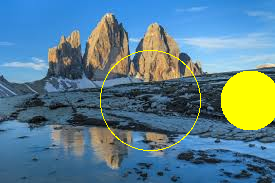

In [62]:
# cerchio = ellisse con entrambi i fuochi nello stesso punto e somma delle distanze = 2 raggio
def draw_circle(img, x, y, r, colore):
    draw_ellisse(img, x, y, x, y, 2*r, colore)

def draw_circle_vuoto(img, x, y, r, colore):
    draw_ellisse_vuota(img, x, y, x, y, 2*r, colore)

img = images.load('3cime.png')
draw_circle_vuoto(img, 150, 100, 50,  yellow)
draw_circle(img, 250, 100, 30,  yellow)

images.visd(img)

## Come disegnare una parabola? una iperbole? una funzione generica?
per esercizio, basta che vi ricordiate le funzioni e usiate draw_pixel

In [63]:
# NEXT lesson: manipolazione immagini ed effetti grafici
# gray
# blur
# contrast
# pixellation
# random noise
# lens
# edge

# Quesito con la Susi 965
![](Susi-965.jpeg)

## Idea di soluzione "brute force" (esplorando tutte le possibili soluzioni)
- trovo tutte le permutazioni delle 6 cifre (sono solo $6!=720$)
- per ciascuna permutazione calcolo i 5 prodotti richiesti
- e controllo che diano tutti come risultato un numero con quelle stesse cifre

Mi serve di:
- calcolare un numero data la sequenza di cifre
- calcolare il prodotto
- spezzare il risultato nelle sue cifre
- controllare che due gruppi di cifre siano uguali

In [64]:
# per ottenere le permutazioni sfrutto il modulo itertools
from itertools import permutations     # vedremo più in là come generarle noi
cifre = [1, 2, 4, 5, 7, 8]
permutazioni = list(permutations(cifre))
print('Le permutazioni sono:', len(permutazioni),permutazioni,sep='\n')

Le permutazioni sono:
720
[(1, 2, 4, 5, 7, 8), (1, 2, 4, 5, 8, 7), (1, 2, 4, 7, 5, 8), (1, 2, 4, 7, 8, 5), (1, 2, 4, 8, 5, 7), (1, 2, 4, 8, 7, 5), (1, 2, 5, 4, 7, 8), (1, 2, 5, 4, 8, 7), (1, 2, 5, 7, 4, 8), (1, 2, 5, 7, 8, 4), (1, 2, 5, 8, 4, 7), (1, 2, 5, 8, 7, 4), (1, 2, 7, 4, 5, 8), (1, 2, 7, 4, 8, 5), (1, 2, 7, 5, 4, 8), (1, 2, 7, 5, 8, 4), (1, 2, 7, 8, 4, 5), (1, 2, 7, 8, 5, 4), (1, 2, 8, 4, 5, 7), (1, 2, 8, 4, 7, 5), (1, 2, 8, 5, 4, 7), (1, 2, 8, 5, 7, 4), (1, 2, 8, 7, 4, 5), (1, 2, 8, 7, 5, 4), (1, 4, 2, 5, 7, 8), (1, 4, 2, 5, 8, 7), (1, 4, 2, 7, 5, 8), (1, 4, 2, 7, 8, 5), (1, 4, 2, 8, 5, 7), (1, 4, 2, 8, 7, 5), (1, 4, 5, 2, 7, 8), (1, 4, 5, 2, 8, 7), (1, 4, 5, 7, 2, 8), (1, 4, 5, 7, 8, 2), (1, 4, 5, 8, 2, 7), (1, 4, 5, 8, 7, 2), (1, 4, 7, 2, 5, 8), (1, 4, 7, 2, 8, 5), (1, 4, 7, 5, 2, 8), (1, 4, 7, 5, 8, 2), (1, 4, 7, 8, 2, 5), (1, 4, 7, 8, 5, 2), (1, 4, 8, 2, 5, 7), (1, 4, 8, 2, 7, 5), (1, 4, 8, 5, 2, 7), (1, 4, 8, 5, 7, 2), (1, 4, 8, 7, 2, 5), (1, 4, 8, 7, 5, 2), (1, 5, 2, 4, 

In [65]:
Sequenza = list[int] | tuple[int,...]     # voglio usare tuple oppure liste
def calcola(cifre : Sequenza) -> int:
    'per convertire le cifre in numero passo per la stringa corrisponente'
    return int(''.join(map(str,cifre))) # concateno e converto in intero

def scomponi(numero : int) -> Sequenza:
    'per scomporre un numero nelle sue cifre passo per la stringa'
    return list(map(int, str(numero)))  # converto tutto in stringa e poi in intero un carattere per volta

# Esempio
calcola((4, 7, 2, 5, 1)), scomponi(123456)

(47251, [1, 2, 3, 4, 5, 6])

In [66]:
def controlla(permutazione : Sequenza, X : int, verbose : bool=False) -> bool:
    'controllo che il prodotto della permutazione per X dia le stesse cifre'
    N = calcola(permutazione)                     # ottengo il numero
    cifre = scomponi(N*X)                         # moltiplico e scompongo
    if verbose: print(f"{N} x {X} = {N*X}")       # se voglio visualizzo il prodotto
    return sorted(cifre) == sorted(permutazione)  # verifico che siano le stesse cifre (i set non vanno bene)

# esempi presi dal quesito della Susi
controlla([1, 5, 3, 8, 4, 6], 3, True), controlla([1, 5, 3, 8, 4, 6], 4, True)

153846 x 3 = 461538
153846 x 4 = 615384


(True, True)

In [67]:
%%time
# e finalmente controlliamo tutte le permutazioni
for p in permutazioni:
    prodotti = [2, 3, 4, 5, 6]
    if all( controlla(p,X) for X in prodotti ):
        for X in prodotti:
            controlla(p,X,True)   # stampo il prodotto

# la soluzione è unica!

142857 x 2 = 285714
142857 x 3 = 428571
142857 x 4 = 571428
142857 x 5 = 714285
142857 x 6 = 857142
CPU times: user 1.59 ms, sys: 11 μs, total: 1.6 ms
Wall time: 1.62 ms


## In realtà potremmo dedurre alcune cose e restringere l'esplorazione
Le cifre disponibili sono [1, 2, 4, 5, 7, 8]
- ABCDEF * 5 = numero che finisce per 5 o per 0
  - 0 non è presente, il risultato finisce per forza con 5
  - F = deve essere dispari (1,5,7)
- ABCDEF * 2 = numero pari (2,4,8)
- ABCDEF * 4 = numero pari (2,4,8)
- ABCDEF * 6 = numero pari (2,4,8) non ammette F=1 o F=5 che darebbero 0 oppure 6 che non sono presenti
  - quindi **F=7**
- ABCDEF * 3 = numero che finisce per 1 OK

Inoltre **A** deve essere **1** altrimenti **A*6** dà riporto

Quindi sappiamo che **F=7 e A=1** 
per cui possiamo rendere la ricerca più veloce 
esaminando solo le 24 permutazioni delle altre 4 cifre [4,2,8,5]

In [68]:
%%time 
for p in permutations([2,4,8,5]):
    cifre = [1, *p, 7]
    if all( controlla(cifre,X) for X in [2,3,4,5,6] ):
        for X in prodotti:
            controlla(cifre,X,True)

142857 x 2 = 285714
142857 x 3 = 428571
142857 x 4 = 571428
142857 x 5 = 714285
142857 x 6 = 857142
CPU times: user 117 μs, sys: 2 μs, total: 119 μs
Wall time: 119 μs
